# 05 · 샘플링으로 최적화하기 — MPPI의 핵심

> 미분을 쓰지 않아도 된다. 후보를 많이 뽑아 비용이 낮은 후보에 큰 가중치를 주고 평균을 내면 더 좋은 입력열이 나온다. 이를 반복하는 것이 MPPI다.

**지금 위치**

01 상태·입력·모델 → 02 비용 → 03 최적화 → 04 MPC → **05 MPPI 핵심** → 06 장애물 → 07 실전 디테일 → 08~09 로봇팔 → 10~13 프로젝트

**이 노트를 끝내면**
1. 경사하강이 곤란한 비용이 어떤 것인지 예를 들 수 있다.
2. "평균 주변에서 샘플링 → 비용 → softmax 가중치 → 가중평균" 한 번의 갱신을 직접 코드로 쓸 수 있다.
3. 온도 β와 탐색 폭 σ가 각각 무엇을 바꾸는지 설명할 수 있다.
4. MPPI를 04의 MPC 루프에 넣어 카트를 제어할 수 있다.

**필요한 것:** [01](01_state_input_model.ipynb) rollout, [02](02_cost_function.ipynb) 비용 함수, [03](03_optimization.ipynb) 비용 지형·경사하강, [04](04_mpc.ipynb) MPC 루프 · **예상 시간:** 50분

## 복습 퀴즈

<details><summary>1. 경사하강은 다음에 어느 방향으로 갈지를 무엇으로 정하나?</summary>

비용의 기울기(gradient). 비용이 가장 빨리 줄어드는 방향, 즉 기울기의 반대 방향으로 조금 이동한다.
</details>

<details><summary>2. MPC는 매 스텝 무엇을 하나?</summary>

현재 상태에서 horizon 길이의 입력열을 최적화하고, 그중 첫 입력만 실행한 뒤 다음 스텝에 다시 계획한다.
</details>

<details><summary>3. MPC의 최적화가 빨라야 하는 이유는?</summary>

매 스텝마다 다시 풀어야 하기 때문이다. 로봇이 1초에 60번 명령을 받는다면 최적화 한 번에 쓸 수 있는 시간은 약 16 ms다.
</details>

In [1]:
import time
import numpy as np
from common import setup_plot
from course import cart_rollout, cart_step, cart_cost, run_mpc, DT
plt = setup_plot()
rng = np.random.default_rng(0)
x0 = np.array([0.0, 0.0])

## 1. 문제 — 기울기가 길을 알려주지 않는 비용

### 문제
카트를 1 m 지점에 세우는데, 이번에는 규칙이 하나 더 있다. **속도가 0.8 m/s를 넘으면 안 된다.** 넘은 스텝마다 벌점 100을 준다.

이 벌점은 "넘었다/안 넘었다"만 본다. 속도가 0.5든 0.79든 벌점은 0이고, 0.81이 되는 순간 100으로 뛴다. 03의 경사하강으로 풀면 어떻게 될까?

**예측해 보기:** 처음에 카트는 멈춰 있어서 속도가 0이다. 이 지점에서 벌점 항의 기울기는 얼마일까? 경사하강은 속도 제한을 지킬까?

In [2]:
T = 20
V_MAX = 0.8

def cost_speed_limit(U):
    # 02의 카트 비용 + 속도 제한 벌점 (넘은 스텝마다 100)
    X = cart_rollout(x0, U)
    over = (X[..., 1:, 1] > V_MAX).sum(-1)
    return cart_cost(X, U) + 100.0 * over

def numerical_grad(f, U, eps=1e-4):
    # 03에서 만든 수치 미분
    g = np.zeros_like(U)
    for i in range(len(U)):
        e = np.zeros_like(U); e[i] = eps
        g[i] = (f(U + e) - f(U - e)) / (2 * eps)
    return g

U_gd = np.zeros(T)
for it in range(300):                      # 03의 경사하강
    U_gd = U_gd - 0.05 * numerical_grad(cost_speed_limit, U_gd)
X_gd = cart_rollout(x0, U_gd)
print('경사하강 결과: 최종 위치 %.3f m, 최고 속도 %.3f m/s, 제한 넘은 스텝 %d개, 비용 %.1f' % (
    X_gd[-1, 0], X_gd[:, 1].max(), (X_gd[1:, 1] > V_MAX).sum(), cost_speed_limit(U_gd)))

경사하강 결과: 최종 위치 1.023 m, 최고 속도 1.159 m/s, 제한 넘은 스텝 8개, 비용 804.4


**결과 해석:** 경사하강은 속도 제한을 무시하고 0.8 m/s를 훌쩍 넘었다. 벌점 항은 대부분의 곳에서 **평평하기** 때문이다. 평평한 곳의 기울기는 0이니 경사하강에게 벌점은 보이지 않는다. 경계를 막 넘는 순간에만 기울기가 생기는데, 그 값은 엄청나게 크거나 0이라서 쓸모가 없다.

실제 로봇 비용에는 이런 항이 많다.
- 장애물 비용은 멀리 떨어져 있으면 0이다. 평평해서 기울기가 0이다.
- "충돌했나/안 했나" 같은 판정은 계단 모양이다.
- 지도에서 읽은 거리처럼 식으로 미분하기 어려운 값도 있다.

**계산 방식의 문제도 있다.** 경사하강은 한 걸음씩 차례로 가야 한다. 이번 걸음의 기울기를 알아야 다음 걸음을 정할 수 있다. 01에서 본 것처럼 rollout은 수백 개를 **동시에** 계산할 수 있는데, 경사하강은 이 장점을 살리기 어렵다.

> **필요한 것:** 기울기 없이 비용 값만 보고, 많은 후보를 동시에 평가해서 좋은 입력열을 찾는 방법.

## 2. 아이디어 1 — 무작위로 많이 던져 보기

### 아이디어
가장 단순한 방법은 이렇다. 입력열을 무작위로 많이 만들어 각각 rollout하고 비용을 계산한 뒤, 가장 싼 것을 고른다. 이를 **무작위 슈팅**(random shooting)이라고 한다. 기울기가 필요 없고, 후보는 모두 동시에 계산할 수 있다.

눈으로 보기 위해 03처럼 입력을 **2개**($T=2$)로 줄인다. 그래야 비용을 $(u_0, u_1)$ 평면 위의 색 지도로 그릴 수 있다(밝을수록 비용이 낮다). 입력 2개로 1 m를 가야 하니 한 스텝을 0.5초로 길게 잡는다.

격자에서 찾은 최적 입력 (u0, u1) = (3.9, -3.7), 비용 0.562
무작위 최선 (3.45, -3.13), 비용 0.674


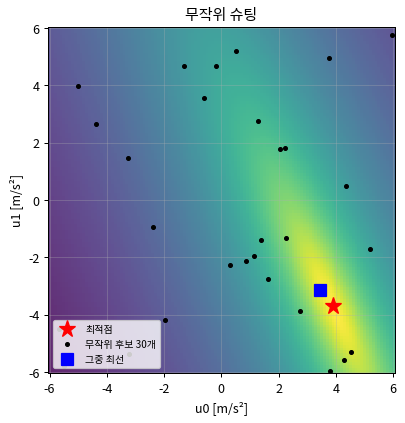

In [3]:
DT2 = 0.5

def J2(U):
    # T=2 카트 비용. U[..., 2] -> J[...]
    return cart_cost(cart_rollout(x0, U, dt=DT2), U)

g = np.linspace(-6, 6, 121)
G0, G1 = np.meshgrid(g, g)
Jgrid = J2(np.stack([G0, G1], axis=-1))
i_min = np.unravel_index(Jgrid.argmin(), Jgrid.shape)
U_star = np.array([G0[i_min], G1[i_min]])
print('격자에서 찾은 최적 입력 (u0, u1) = (%.1f, %.1f), 비용 %.3f' % (*U_star, Jgrid.min()))

def draw_landscape(ax):
    ax.pcolormesh(G0, G1, np.log(Jgrid), shading='auto', cmap='viridis_r', alpha=0.85)   # 밝을수록 비용이 낮다
    ax.plot(*U_star, 'r*', ms=14, label='최적점')
    ax.set_xlabel('u0 [m/s²]'); ax.set_ylabel('u1 [m/s²]'); ax.set_aspect('equal')

K = 30
U_rand = rng.uniform(-6, 6, size=(K, 2))
J_rand = J2(U_rand)
fig, ax = plt.subplots(figsize=(5, 5))
draw_landscape(ax)
ax.plot(U_rand[:, 0], U_rand[:, 1], 'k.', label='무작위 후보 30개')
ax.plot(*U_rand[J_rand.argmin()], 'bs', ms=9, label='그중 최선')
ax.legend(fontsize=8, loc='lower left'); ax.set_title('무작위 슈팅'); plt.show()
print('무작위 최선 (%.2f, %.2f), 비용 %.3f' % (*U_rand[J_rand.argmin()], J_rand.min()))

**결과 해석:** 운이 좋으면 최적점 근처에 떨어진 후보가 있지만, 대부분의 후보는 전혀 상관없는 곳에 낭비된다.

**예측해 보기:** 입력이 2개가 아니라 20개($T=20$)라면, 같은 후보 수로 무작위 슈팅을 해도 쓸 만한 결과가 나올까?

In [4]:
def best_random_cost(T_, K_, trials=20):
    # 후보 K_개 무작위 슈팅을 trials번 반복한 최선 비용의 평균 (같은 1 m 문제, 전체 시간 1초로 고정)
    dt_ = 1.0 / T_
    out = []
    for _ in range(trials):
        U = rng.uniform(-6, 6, size=(K_, T_))
        out.append(cart_cost(cart_rollout(x0, U, dt=dt_), U, w_goal=1.0 / T_).min())
    return np.mean(out)

for T_ in [2, 5, 20]:
    print('T=%2d: ' % T_ + ', '.join('K=%4d → %.2f' % (K_, best_random_cost(T_, K_)) for K_ in [30, 300, 3000]))

T= 2: K=  30 → 0.82, K= 300 → 0.48, K=3000 → 0.43
T= 5: K=  30 → 2.07, K= 300 → 1.07, K=3000 → 0.90
T=20: K=  30 → 4.72, K= 300 → 3.60, K=3000 → 3.02


**결과 해석:** 입력 개수가 늘면 같은 후보 수로 찾은 최선의 비용이 크게 나빠진다. 후보를 100배로 늘려도 조금 나아질 뿐이다. 공간이 차원마다 곱으로 넓어지기 때문이다. 이를 **차원의 저주**라고 한다. 로봇팔은 30스텝 × 7관절 = 210개의 입력을 정해야 하니, 무작위로 던져서는 답이 없다.

**한 문장으로:** 무작위 슈팅의 장점 하나와 단점 하나를 말해 보자.

## 3. 아이디어 2 — 지금 추측 주변에서 던지고, 좋은 것들의 평균으로 옮기기

### 아이디어
아무 데나 던지지 말자. **지금 가장 좋다고 생각하는 입력열**(평균 $\mu$) 주변에만 후보를 뿌린다. 퍼지는 정도는 표준편차 $\sigma$로 정한다.

$$
U_k = \mu + \sigma\,\epsilon_k, \qquad \epsilon_k \sim \mathcal{N}(0, 1)
$$

말로 하면, 평균에 "평균 0, 표준편차 1인 무작위 수"를 σ배 해서 더한 것이 후보 $k$다.

그다음 비용이 낮은 후보 **상위 몇 개**(예: 10개)의 평균을 새 $\mu$로 삼는다. 좋은 후보들이 몰린 쪽으로 평균이 옮겨 간다. 이것을 반복한다.

8회 후 μ = (3.36, -2.20), 비용 0.835 (최적 0.562)


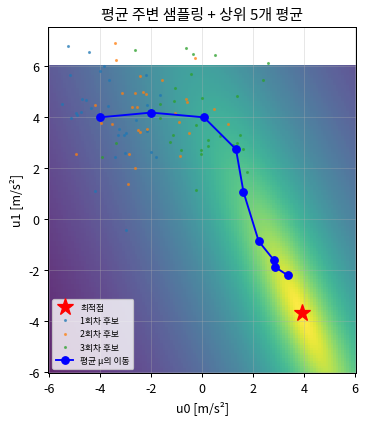

In [5]:
def topk_step(mu, sigma, cost_fn, K, n_elite):
    U = mu + sigma * rng.standard_normal((K,) + mu.shape)   # 평균 주변 샘플
    J = cost_fn(U)
    elite = U[np.argsort(J)[:n_elite]]                      # 비용 낮은 상위 n_elite개
    return elite.mean(axis=0), U, J

mu = np.array([-4.0, 4.0])          # 일부러 엉뚱한 곳에서 시작
path = [mu]
fig, ax = plt.subplots(figsize=(5, 5))
draw_landscape(ax)
for it in range(8):
    mu, U, J = topk_step(mu, 1.5, J2, K=30, n_elite=5)
    if it < 3:
        ax.plot(U[:, 0], U[:, 1], '.', ms=3, alpha=0.6, label=f'{it+1}회차 후보')
    path.append(mu)
path = np.array(path)
ax.plot(path[:, 0], path[:, 1], 'bo-', label='평균 μ의 이동')
ax.legend(fontsize=7, loc='lower left'); ax.set_title('평균 주변 샘플링 + 상위 5개 평균'); plt.show()
print('8회 후 μ = (%.2f, %.2f), 비용 %.3f (최적 %.3f)' % (*mu, J2(mu), Jgrid.min()))

**결과 해석:** 후보 30개씩 8번, 모두 240번만 평가하고도 최적점 근처로 왔다. 매번 좋은 쪽으로 조금씩 옮겨 가기 때문이다. 이 방식은 **교차 엔트로피 방법**(CEM, cross-entropy method)이라는 이름으로 쓰인다.

### 남은 문제
"상위 5개"라는 기준은 칼같이 자른다. 5등과 6등의 비용이 거의 같아도 5등은 평균에 100% 반영되고 6등은 0%다. 몇 개를 고를지도 따로 정해야 한다. 비용 차이에 비례해서 **부드럽게** 반영할 수는 없을까?

## 4. 아이디어 3 — 비용을 가중치로: softmax와 온도 β

### 아이디어
후보마다 가중치 $\omega_k$를 준다. 비용이 낮을수록 크게, 모두 더하면 1이 되게 만든다. 가장 널리 쓰는 방법은 지수 함수를 쓰는 것이다.

$$
\omega_k = \frac{\exp\!\big(-(J_k - J_{\min})/\beta\big)}{\sum_j \exp\!\big(-(J_j - J_{\min})/\beta\big)}
$$

한 부분씩 풀어 보자.
- $J_k - J_{\min}$: 가장 좋은 후보보다 얼마나 나쁜가. 최선 후보는 0이다.
- $\exp(-\cdot/\beta)$: 차이가 0이면 1, 차이가 클수록 0에 가까워진다. 항상 양수다.
- 분모: 모두 더해 1이 되도록 나눈다.

이 계산을 **softmax**라고 부르고, $\beta$를 **온도**(temperature)라고 부른다. 온도는 "비용 차이를 얼마나 엄격하게 볼지"를 정한다.

**숫자로 확인:** 후보 4개의 비용이 1.0, 1.2, 3.0, 10.0일 때
- β=0.1: 차이 0.2도 크게 본다. 가중치는 거의 최선 하나에 몰린다.
- β=1: 비용이 비슷한 1등과 2등이 나눠 갖는다.
- β=10: 차이를 거의 무시한다. 네 후보가 비슷하게 받는다.

**예측해 보기:** 아래 막대그래프에서 β가 커질수록 막대 모양이 어떻게 바뀔까?

β=0.1  가중치 [0.881 0.119 0.    0.   ], 합 1.00
β=1.0  가중치 [0.512 0.419 0.069 0.   ], 합 1.00
β=10.0 가중치 [0.312 0.306 0.255 0.127], 합 1.00


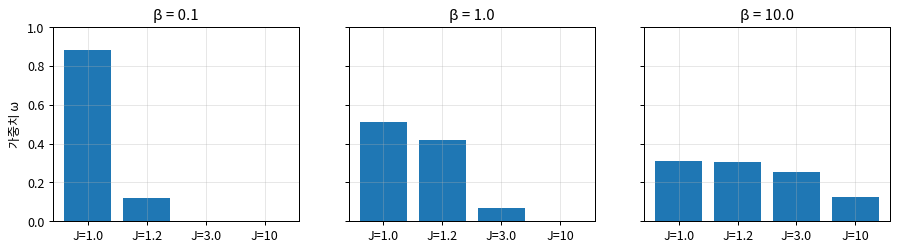

In [6]:
def softmax_weights(J, beta):
    z = np.exp(-(J - J.min()) / beta)
    return z / z.sum()

J_ex = np.array([1.0, 1.2, 3.0, 10.0])
fig, axs = plt.subplots(1, 3, figsize=(12, 2.8), sharey=True)
for ax, beta in zip(axs, [0.1, 1.0, 10.0]):
    w = softmax_weights(J_ex, beta)
    ax.bar(['J=1.0', 'J=1.2', 'J=3.0', 'J=10'], w)
    ax.set_title(f'β = {beta}'); ax.set_ylim(0, 1)
    print('β=%-4s 가중치 %s, 합 %.2f' % (beta, np.round(w, 3), w.sum()))
axs[0].set_ylabel('가중치 ω'); plt.show()

**결과 해석:** β가 작으면 가장 싼 후보 하나만 고르는 것과 같고(상위 1개), β가 크면 모든 후보의 단순 평균에 가깝다. 3절의 "상위 몇 개" 대신 β 하나로 그 사이를 **부드럽게** 조절하는 셈이다.

**왜 $J_{\min}$을 빼나?** 빼지 않아도 분모와 분자에서 같은 값이 약분되어 결과는 같다. 하지만 비용이 1000이면 $e^{-1000}$은 컴퓨터에서 0이 되어 0/0이 된다. 최솟값을 빼면 최선 후보가 항상 $e^0=1$이라 이런 일이 없다.

**β는 비용의 크기와 함께 봐야 한다.** 가중치 비 $\omega_i/\omega_j = e^{-(J_i-J_j)/\beta}$는 비용 **차이**를 β로 나눈 값으로만 정해진다. 비용을 10배 키우면 β도 10배 키워야 같은 결과가 나온다.

## 5. 세 아이디어를 합치면 — MPPI 한 번의 갱신

### 아이디어
2~4절을 합친다.
1. 평균 $\mu$ 주변에서 후보 $K$개를 뽑는다: $U_k = \mu + \sigma\epsilon_k$
2. 각 후보를 rollout해서 비용 $J_k$를 계산한다 (01, 02)
3. 비용으로 가중치 $\omega_k$를 계산한다 (softmax, 온도 β)
4. 가중평균으로 평균을 옮긴다: $\mu \leftarrow \sum_k \omega_k U_k$

이 갱신을 몇 번 반복하는 방법이 **MPPI**(Model Predictive Path Integral)다. 이름의 "path integral"은 이 식이 유도된 물리·확률 이론에서 온 것이다. 쓰는 데에는 위 네 줄만 알면 된다.

8회 후 μ = (3.43, -2.66), 비용 0.687 (최적 0.562)


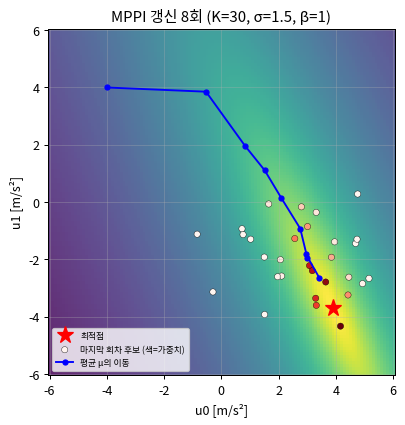

In [7]:
def mppi_step(mu, sigma, cost_fn, K, beta):
    eps = rng.standard_normal((K,) + mu.shape)
    U = mu + sigma * eps                         # 1. 평균 주변 후보 K개
    J = cost_fn(U)                               # 2. rollout + 비용
    w = softmax_weights(J, beta)                 # 3. 가중치
    w_b = w.reshape((K,) + (1,) * mu.ndim)
    mu_new = (w_b * U).sum(axis=0)               # 4. 가중평균
    return mu_new, U, J, w

mu = np.array([-4.0, 4.0]); path = [mu]
for it in range(8):
    mu, U, J, w = mppi_step(mu, 1.5, J2, K=30, beta=1.0)
    path.append(mu)
path = np.array(path)

fig, ax = plt.subplots(figsize=(5, 5))
draw_landscape(ax)
sc = ax.scatter(U[:, 0], U[:, 1], c=w, cmap='Reds', s=25, edgecolors='k', linewidths=0.3, label='마지막 회차 후보 (색=가중치)')
ax.plot(path[:, 0], path[:, 1], 'bo-', ms=4, label='평균 μ의 이동')
ax.legend(fontsize=7, loc='lower left'); ax.set_title('MPPI 갱신 8회 (K=30, σ=1.5, β=1)'); plt.show()
print('8회 후 μ = (%.2f, %.2f), 비용 %.3f (최적 %.3f)' % (*mu, J2(mu), Jgrid.min()))

**결과 해석:** 3절처럼 평균이 최적점 쪽으로 이동했다. 차이는 모든 후보가 비용에 따라 조금씩 기여한다는 점이다. 마지막 그림에서 최적점 가까운 후보일수록 진하게(가중치가 크게) 칠해져 있다.

**한 문장으로:** MPPI 한 번의 갱신을 "샘플, 비용, 가중치, 평균"이라는 네 단어를 써서 설명해 보자.

## 6. β와 σ — 두 손잡이

MPPI에는 사람이 정하는 값이 두 개 있다.
- **σ (탐색 폭):** 평균 주변 얼마나 넓게 후보를 뿌릴지
- **β (온도):** 후보의 비용 차이를 얼마나 엄격하게 볼지

**예측해 보기:** 아래 네 조합 중 최적점에 가장 가깝게 가는 것은? σ가 아주 작으면 무슨 일이 생길까?

σ     β      | 8회 후 비용 (seed 5개 평균 ± 표준편차)   최적 0.562
0.2   1.0    | 15.257 ± 1.315
1.5   1.0    | 0.968 ± 0.436
4.0   1.0    | 1.032 ± 0.483
1.5   0.01   | 0.662 ± 0.059
1.5   100.0  | 21.411 ± 5.563


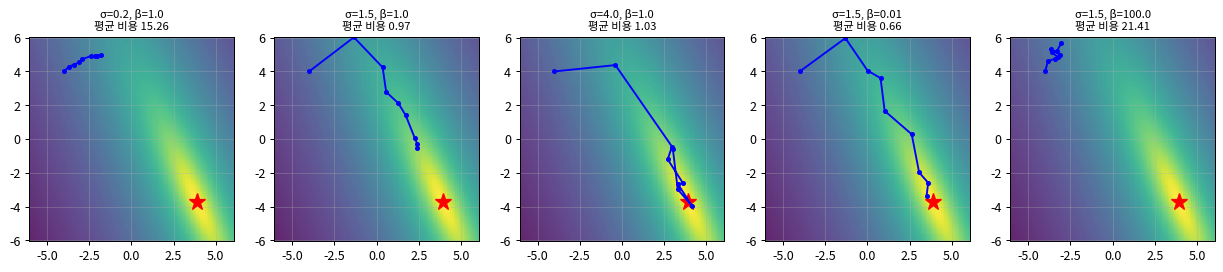

In [8]:
combos = [(0.2, 1.0), (1.5, 1.0), (4.0, 1.0), (1.5, 0.01), (1.5, 100.0)]
fig, axs = plt.subplots(1, len(combos), figsize=(17, 3.6))
print('σ     β      | 8회 후 비용 (seed 5개 평균 ± 표준편차)   최적 %.3f' % Jgrid.min())
for ax, (sigma, beta) in zip(axs, combos):
    finals = []
    for seed in range(5):
        rng = np.random.default_rng(seed)
        mu = np.array([-4.0, 4.0]); path = [mu]
        for it in range(8):
            mu, U, J, w = mppi_step(mu, sigma, J2, K=30, beta=beta)
            path.append(mu)
        finals.append(J2(mu))
        if seed == 0:
            draw_landscape(ax)
            ax.plot(*np.array(path).T, 'bo-', ms=3)
    print('%-5s %-6s | %.3f ± %.3f' % (sigma, beta, np.mean(finals), np.std(finals)))
    ax.set_title(f'σ={sigma}, β={beta}\n평균 비용 {np.mean(finals):.2f}', fontsize=9)
    ax.set_xlabel(''); ax.set_ylabel('')
plt.show()

**결과 해석** (표의 숫자를 보며. 시작점 (−4, 4)의 비용은 약 46.6, 최적은 0.56)
- **σ가 너무 작으면(0.2)** 한 번에 조금씩밖에 못 움직인다. 8번 갱신해도 비용이 15 근처에 머문다.
- **σ가 크면(4.0)** 최적점 근처까지는 가지만 결과가 seed마다 많이 흔들린다(표준편차가 큼). 후보가 넓게 퍼져서 최적점 바로 옆에 떨어지는 후보가 적기 때문이다.
- **β가 아주 작으면(0.01)** 매번 가장 좋은 후보 하나로 평균을 옮긴다. **이 문제에서는 오히려 가장 좋았다.** 비용이 매끈하고 잡음이 없어서 "가장 싼 후보"를 믿어도 되기 때문이다. 하지만 모델이 부정확하거나 후보가 적어 비용 순위를 믿기 어려운 상황에서는 후보 하나에 모든 것을 걸게 되어 흔들리기 쉽다. 그래서 실제로는 적당히 큰 β로 여러 후보를 섞는다.
- **β가 아주 크면(100)** 모든 후보의 단순 평균에 가까워져서 비용 정보를 거의 쓰지 않는다. 8번 갱신해도 비용이 시작점의 절반 정도인 21 근처에 머문다.

좋은 값은 문제(비용의 크기, 입력의 범위, 모델의 정확도)에 따라 다르다. 07 노트에서 σ를 상황에 맞게 바꾸는 방법을 다룬다.

## 7. 입력 20개짜리 문제로 — 1절의 속도 제한 다시

이제 원래 문제($T=20$, 속도 제한 0.8 m/s)로 돌아간다. 1절에서 경사하강이 실패한 바로 그 비용이다. MPPI는 비용 **값**만 쓰므로, 평평하거나 계단 모양인 벌점도 그대로 반영할 수 있다.

MPPI   : 최종 위치 0.940 m, 최고 속도 0.652 m/s, 제한 넘은 스텝 0개, 비용 6.2
경사하강: 최종 위치 1.023 m, 최고 속도 1.159 m/s, 제한 넘은 스텝 8개, 비용 804.4


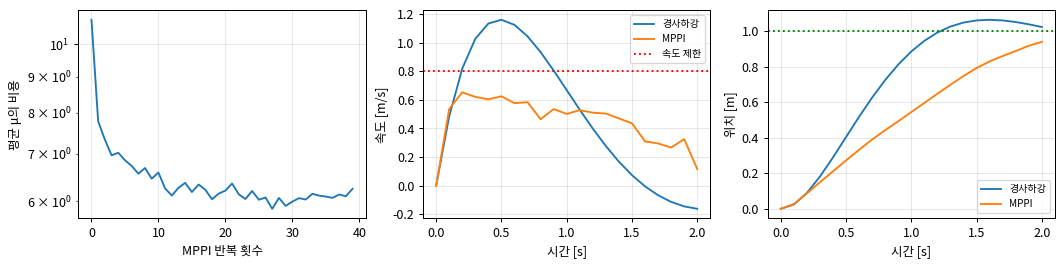

In [9]:
rng = np.random.default_rng(0)
mu = np.zeros(T)
history = []
for it in range(40):
    mu, U, J, w = mppi_step(mu, 1.0, cost_speed_limit, K=300, beta=1.0)
    history.append(cost_speed_limit(mu))
X_mppi = cart_rollout(x0, mu)

print('MPPI   : 최종 위치 %.3f m, 최고 속도 %.3f m/s, 제한 넘은 스텝 %d개, 비용 %.1f' % (
    X_mppi[-1, 0], X_mppi[:, 1].max(), (X_mppi[1:, 1] > V_MAX).sum(), cost_speed_limit(mu)))
print('경사하강: 최종 위치 %.3f m, 최고 속도 %.3f m/s, 제한 넘은 스텝 %d개, 비용 %.1f' % (
    X_gd[-1, 0], X_gd[:, 1].max(), (X_gd[1:, 1] > V_MAX).sum(), cost_speed_limit(U_gd)))

t_x = np.arange(T + 1) * DT
fig, axs = plt.subplots(1, 3, figsize=(14, 3))
axs[0].plot(history); axs[0].set_xlabel('MPPI 반복 횟수'); axs[0].set_ylabel('평균 μ의 비용'); axs[0].set_yscale('log')
axs[1].plot(t_x, X_gd[:, 1], label='경사하강'); axs[1].plot(t_x, X_mppi[:, 1], label='MPPI')
axs[1].axhline(V_MAX, color='r', ls=':', label='속도 제한'); axs[1].set_ylabel('속도 [m/s]'); axs[1].legend(fontsize=8)
axs[2].plot(t_x, X_gd[:, 0], label='경사하강'); axs[2].plot(t_x, X_mppi[:, 0], label='MPPI')
axs[2].axhline(1.0, color='g', ls=':'); axs[2].set_ylabel('위치 [m]'); axs[2].legend(fontsize=8)
for a in axs[1:]: a.set_xlabel('시간 [s]')
plt.show()

**결과 해석:** MPPI는 속도를 제한 아래(최고 약 0.65 m/s)로 유지하면서 카트를 1 m 근처(약 0.94 m)로 보낸다. 제한을 넘는 후보는 비용이 100 이상 비싸서 가중치가 거의 0이 되기 때문이다. 경사하강에게는 보이지 않던 벌점이 MPPI에게는 "비싼 후보"로 보인다.

대신 MPPI의 답은 무작위 샘플에 기대므로 매번 조금씩 다르고, 정확한 최적점에 딱 맞지는 않는다. 로봇 제어에서는 "매 스텝 빠르게, 충분히 좋은 답"이 더 중요해서 이 성질을 받아들인다.

## 8. MPC 안에 넣기

### 아이디어
04의 MPC 루프에서 `plan` 함수만 MPPI로 바꾼다. 매 스텝 MPPI 갱신을 **몇 번만**(여기서는 3번) 하고 평균 $\mu$의 첫 입력을 실행한다. 다음 스텝에서는 μ를 한 칸 당겨서(04의 warm start) 다시 시작한다. 직전 계획이 이미 좋은 출발점이라 몇 번의 갱신으로 충분하다.

실제 시스템은 01의 **마찰 있는 카트**다. 모델(마찰 없음)과 실제가 달라도 MPC가 매번 다시 계획해서 따라잡는지 확인한다.

50스텝 MPC: 최종 위치 0.999 m, 최종 속도 0.024 m/s, 최고 속도 0.604 m/s
스텝당 계산 시간 1.2 ms (후보 200개 × 3회 = rollout 600개)


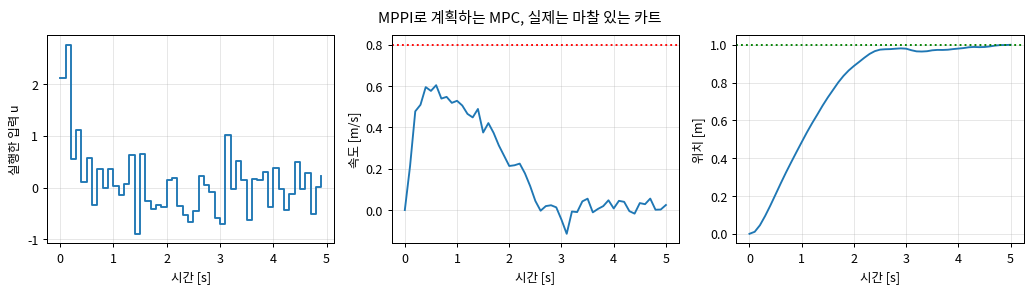

In [10]:
def real_cart_step(x, u, friction=0.5):
    # 01의 '실제 카트': 모델에 없는 마찰이 있다
    return cart_step(x, u - friction * x[..., 1])

def make_mppi_plan(K=200, sigma=1.0, beta=1.0, n_iters=3):
    def plan(x, mu):
        cost_fn = lambda U: cost_speed_limit_from(x, U)
        for _ in range(n_iters):
            mu, _, _, _ = mppi_step(mu, sigma, cost_fn, K, beta)
        return mu
    return plan

def cost_speed_limit_from(x, U):
    # 1절과 같은 비용, 시작 상태만 현재 상태 x로
    X = cart_rollout(x, U)
    return cart_cost(X, U) + 100.0 * (X[..., 1:, 1] > V_MAX).sum(-1)

rng = np.random.default_rng(0)
t0 = time.perf_counter()
xs, us, plans = run_mpc(make_mppi_plan(), x0, steps=50, plant_step=real_cart_step, U_init=np.zeros(T))
elapsed = time.perf_counter() - t0
print('50스텝 MPC: 최종 위치 %.3f m, 최종 속도 %.3f m/s, 최고 속도 %.3f m/s' % (xs[-1, 0], xs[-1, 1], xs[:, 1].max()))
print('스텝당 계산 시간 %.1f ms (후보 200개 × 3회 = rollout 600개)' % (1000 * elapsed / 50))

t_mpc = np.arange(len(xs)) * DT
fig, axs = plt.subplots(1, 3, figsize=(14, 3))
axs[0].step(t_mpc[:-1], us, where='post'); axs[0].set_ylabel('실행한 입력 u');
axs[1].plot(t_mpc, xs[:, 1]); axs[1].axhline(V_MAX, color='r', ls=':'); axs[1].set_ylabel('속도 [m/s]')
axs[2].plot(t_mpc, xs[:, 0]); axs[2].axhline(1.0, color='g', ls=':'); axs[2].set_ylabel('위치 [m]')
for a in axs: a.set_xlabel('시간 [s]')
fig.suptitle('MPPI로 계획하는 MPC, 실제는 마찰 있는 카트'); plt.show()

**결과 해석:** 모델에 없는 마찰이 있어도 카트는 1 m 근처에서 멈춘다. 속도도 제한 아래(최고 약 0.6 m/s)를 유지한다. 다만 벌점은 금지가 아니라 비용이라서(soft), 다른 이득이 충분히 크면 넘는 후보가 선택될 수도 있다. 04에서 배운 "매 스텝 다시 계획"이 모델 오차를 보정하고, 05의 MPPI가 매 스텝 그 계획을 빠르게 세운다.

실행한 입력(왼쪽)이 조금 들쭉날쭉한 것은 샘플이 무작위라서다. 07 노트에서 이것을 매끄럽게 만드는 방법을 배운다.

**직접 해보기**
1. `make_mppi_plan(n_iters=1)`로 바꿔 보자. 스텝당 갱신 1번으로도 될까?
2. `beta=0.01`, `beta=100`으로 바꿔 6절의 결과와 비교해 보자.
<details><summary>예상 결과</summary>

1. warm start 덕분에 1번으로도 대체로 목표에 가지만, 처음 몇 스텝의 반응이 느리거나 더 들쭉날쭉할 수 있다.
2. β가 아주 크면 평균이 잘 안 움직여서 목표에 늦게 가거나 못 간다. 아주 작으면 매번 단일 후보를 따라가서 입력이 더 들쭉날쭉해진다.
</details>

## 핵심 정리

- 경사하강은 평평하거나 계단 모양인 비용(장애물·충돌 판정·제한 벌점)에서 길을 잃고, 차례로만 계산할 수 있다.
- **MPPI 한 번의 갱신:** 평균 μ 주변에서 후보 K개를 뽑고($\mu+\sigma\epsilon$) → rollout과 비용 계산 → **softmax 가중치** $\omega_k \propto e^{-(J_k-J_{\min})/\beta}$ → 가중평균으로 μ를 옮긴다.
- **σ**는 탐색 폭, **β**(온도)는 비용 차이를 얼마나 엄격하게 볼지를 정한다. β→0이면 최선 후보 하나, β→∞이면 단순 평균.
- 후보는 모두 동시에 계산할 수 있어서 GPU에서 빠르다. MPC 안에서는 매 스텝 몇 번만 갱신하고 warm start로 이어 간다.

`softmax_weights`, `mppi_step`은 `course.py`에 저장해 두었다. course 버전에는 07에서 쓸 옵션이 더 있고, 반환값이 `(새 평균, 새 σ, info)`라는 점만 다르다.

## 확인 문제

<details><summary>1. 후보 비용이 [5.0, 5.1, 9.0]이고 β=0.1이면 가중치는 대략 어떻게 나뉘나?</summary>

최선(5.0)과 0.1 차이 나는 후보는 $e^{-1}\approx0.37$배, 4.0 차이 나는 후보는 $e^{-40}\approx0$배. 정규화하면 대략 [0.73, 0.27, 0.00].
</details>

<details><summary>2. 비용 함수 전체에 10을 곱했다. 같은 동작을 얻으려면 β를 어떻게 바꿔야 하나?</summary>

β도 10배. 가중치는 비용 차이/β로만 정해지기 때문이다.
</details>

<details><summary>3. MPPI가 장애물 비용이 0인 먼 곳에서도 장애물을 피할 수 있는 이유는?</summary>

기울기가 아니라 후보들의 비용 값을 비교하기 때문이다. 어떤 후보의 미래 궤적이 장애물에 가까워지면 그 후보의 비용이 커지고 가중치가 작아진다. 지금 위치의 기울기가 0이어도 상관없다.
</details>

<details><summary>4. σ를 0으로 두면 MPPI는 어떻게 되나?</summary>

모든 후보가 μ와 같아져서 가중평균도 μ 그대로다. 전혀 움직이지 않는다. 탐색할 폭이 있어야 개선할 수 있다.
</details>

## 실제 프로젝트에서는

cuRobo의 MPPI 설정 파일 `particle_mpc.yml`에서 이 노트의 값들은 다음 이름으로 나온다(09 노트에서 직접 읽어 본다).

| 이 노트 | cuRobo 설정 | 프로젝트 값 |
|---|---|---|
| 후보 수 K | `num_particles` | 400 |
| 스텝당 갱신 횟수 | `n_iters` | 5 |
| 온도 β | `beta` | 0.1 |
| 탐색 폭 σ² (분산) | `init_cov` | 0.05 |
| 가중평균으로 μ 갱신 | `step_size_mean` (07) | 0.9 |

cuRobo에는 이 밖에도 설정이 많다(`gamma`, `sample_mode: BEST`, `halton`, `null_act_frac` …). 각각이 어떤 문제를 해결하는지 06과 07에서 하나씩 문제부터 보여 주며 다룬다.

## 다음 노트

[06 · MPPI로 장애물 피하기](06_mppi_obstacles.ipynb): 1D 카트로 MPPI의 원리를 익혔다. 이제 2D 평면에서 장애물을 피해 보면서, 장애물 비용, 먼 미래의 할인, 평균을 쓸 때의 함정을 배운다.